# 04 — Evaluation and Analysis (REVISI, dipertahankan)

Notebook ini **TIDAK dihapus** — file aslinya dari skripsi tetap ada di `05_evaluation_and_analysis.ipynb` (169 KB, lengkap dengan output lama) dan di `notebooks/archive/`.

Notebook 04 ini adalah versi revisinya untuk rencana baru (biner + XGBoost + scale_pos_weight + TreeSHAP — model final diputuskan 2026-11-18). Isinya sama seperti dulu — classification report per kelas, confusion matrix, distribusi sebelum/sesudah SMOTE-NC, dan feature importance — tapi sekarang untuk 2 kelas dan membandingkan RF (skripsi) vs XGBoost + SHAP.

Jalankan SETELAH notebook 03 selesai (versi scale_pos_weight), karena notebook ini membaca `outputs/tables/perbandingan_model_cv.csv`, `outputs/tables/shap_global.csv`, dan `models/xgb_scaleposweight_binary.pkl` hasil 03.

In [6]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
pd.options.display.float_format='{:.4f}'.format
print('ok — pastikan notebook 03 sudah di-run dulu')

ok — pastikan notebook 03 sudah di-run dulu


In [7]:
# --- 1. Tabel perbandingan CV dari notebook 03 (jangan bandingkan Accuracy 3 kelas vs 2 kelas langsung) ---
res = pd.read_csv('../outputs/tables/perbandingan_model_cv.csv')
display(res.groupby('model').mean(numeric_only=True).round(4))
print('\nBaseline skripsi (3 kelas, dari notebook 05 lama):')
print('RF: Acc 0.8744, BalAcc 0.5982, ROC-AUC 0.9193')
print('RF+SMOTE: Acc 0.8092, BalAcc 0.7343, ROC-AUC 0.9065')

,fold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,
RF + SMOTE-NC,3.0000,0.8171,0.7909,0.4973,0.7502,0.5960,0.9036,0.7122
XGB + SMOTE-NC,3.0000,0.7940,0.7741,0.4558,0.7431,0.5643,0.8743,0.6564
XGB + scale_pos_weight,3.0000,0.8027,0.8210,0.4733,0.8496,0.6074,0.9046,0.7012



Baseline skripsi (3 kelas, dari notebook 05 lama):
RF: Acc 0.8744, BalAcc 0.5982, ROC-AUC 0.9193
RF+SMOTE: Acc 0.8092, BalAcc 0.7343, ROC-AUC 0.9065


In [8]:
# --- 2. Distribusi sebelum / sesudah SMOTE-NC (biner) ---
df = pd.read_csv('../data/processed/inventaris_for_model.csv')
print('Sebelum SMOTE-NC (biner):')
print(df['kondisi_biner'].value_counts().to_dict(), '(Baik 1889, Perlu 412)')
print('Model final TIDAK pakai SMOTE-NC: imbalance ditangani dengan scale_pos_weight = 1889/412 = 4,59 di loss function, data train tetap 1889 vs 412 (asli, tanpa sintetik).')
print('Pembanding SMOTE-NC di train (per fold, contoh): Baik 1889, Perlu 1889 — 50% vs 50% di versi biner.')
print('Di versi 3 kelas lama: Baik/Kurang Baik/Rusak Berat masing-masing 1889 (33.33%) setelah SMOTE.')

Sebelum SMOTE-NC (biner):
{0: 1889, 1: 412} (Baik 1889, Perlu 412)
Model final TIDAK pakai SMOTE-NC: imbalance ditangani dengan scale_pos_weight = 1889/412 = 4,59 di loss function, data train tetap 1889 vs 412 (asli, tanpa sintetik).
Pembanding SMOTE-NC di train (per fold, contoh): Baik 1889, Perlu 1889 — 50% vs 50% di versi biner.
Di versi 3 kelas lama: Baik/Kurang Baik/Rusak Berat masing-masing 1889 (33.33%) setelah SMOTE.


In [9]:
# --- 3. Evaluasi model final (bundle dari notebook 03) di data asli ---
# PERINGATAN: ini evaluasi IN-SAMPLE (model dinilai di data yang sama dengan data
# latihnya) — angkanya akan OPTIMIS. Angka generalisasi yang bisa dipercaya adalah
# CV/OOF dari notebook 03 (BalAcc 0,8210, Recall 0,8495 di thr 0,5 / 0,9005 di thr 0,417).
# Bagian ini hanya sanity check: apakah bundle bisa dimuat dan pipeline-nya konsisten.
try:
    bundle = joblib.load('../models/xgb_scaleposweight_binary.pkl')
    print('bundle final:', bundle.get('model_name'), '| scale_pos_weight:', bundle.get('scale_pos_weight'))
except FileNotFoundError:
    bundle = joblib.load('../models/xgb_smotenc_binary.pkl')
    print('PERINGATAN: bundle SPW belum ada, memakai bundle SMOTE-NC lama — run ulang notebook 03 versi baru dulu.')
model, scaler, enc, ohe = bundle['model'], bundle['scaler'], bundle['encoder'], bundle['onehot']
NUM, CAT = bundle['num_cols'], bundle['cat_cols']
# Imputasi HARUS sama seperti notebook 03 (hierarkis, bukan median mentah):
# mean per nama_barang -> mean per bahan+kategori -> median, lalu depresiasi dihitung ulang.
# Versi lama cell ini pakai median saja — itu meratakan 1.289 harga kosong ke satu angka
# dan membuat recall Perlu jatuh ke 0,31 (salah, bukan kelemahan model).
def hitung_depresiasi(umur, harga_per_unit, kategori):
    if pd.isna(harga_per_unit): return np.nan
    if kategori == 'Elektronik':
        nb = harga_per_unit
        for _ in range(int(umur)): nb -= nb * (2/5)
        return round(min(harga_per_unit - nb, harga_per_unit), 2)
    return round(min((harga_per_unit/10)*umur, harga_per_unit), 2)
d = df.copy()
nama_mean = d.groupby('nama_barang')['harga_per_unit'].mean()
grup_mean = d.groupby(['bahan','kategori'])['harga_per_unit'].mean()
med = d['harga_per_unit'].median()
d['harga_per_unit'] = d['harga_per_unit'].fillna(d['nama_barang'].map(nama_mean))
mask = d['harga_per_unit'].isna()
if mask.any():
    keys = list(zip(d.loc[mask,'bahan'], d.loc[mask,'kategori']))
    d.loc[mask,'harga_per_unit'] = [grup_mean.get(k, np.nan) for k in keys]
d['harga_per_unit'] = d['harga_per_unit'].fillna(med)
d['depresiasi_aset'] = [hitung_depresiasi(r['umur'], r['harga_per_unit'], r['kategori']) for _, r in d.iterrows()]
print('missing setelah imputasi hierarkis:', int(d['harga_per_unit'].isna().sum()), '| depresiasi NaN:', int(d['depresiasi_aset'].isna().sum()))
X_num = scaler.transform(d[NUM]); X_cat = enc.transform(d[CAT])
X = __import__('numpy').hstack([ohe.transform(X_cat), X_num])
proba = model.predict_proba(X)[:, 1]
thr = bundle.get('threshold_f2', 0.5)
for t, label in [(0.5, 'thr 0.5'), (thr, 'thr F2')]:
    pred = (proba > t).astype(int)
    print(f'\n--- {label} (thr={t:.3f}) ---')
    print(classification_report(d['kondisi_biner'], pred, target_names=['Baik','Perlu Pemeliharaan']))
    print('Confusion matrix (baris=aktual, kolom=prediksi):')
    print(confusion_matrix(d['kondisi_biner'], pred))
print('\nCatatan: angka di atas IN-SAMPLE — jangan dikutip sebagai performa generalisasi. Pakai angka CV/OOF notebook 03 untuk laporan.')


bundle final: XGB + scale_pos_weight | scale_pos_weight: 4.584951456310679
missing setelah imputasi hierarkis: 0 | depresiasi NaN: 0

--- thr 0.5 (thr=0.500) ---
                    precision    recall  f1-score   support

              Baik       0.98      0.80      0.88      1889
Perlu Pemeliharaan       0.50      0.92      0.65       412

          accuracy                           0.82      2301
         macro avg       0.74      0.86      0.77      2301
      weighted avg       0.89      0.82      0.84      2301

Confusion matrix (baris=aktual, kolom=prediksi):
[[1514  375]
 [  31  381]]

--- thr F2 (thr=0.417) ---
                    precision    recall  f1-score   support

              Baik       0.99      0.77      0.86      1889
Perlu Pemeliharaan       0.47      0.95      0.63       412

          accuracy                           0.80      2301
         macro avg       0.73      0.86      0.75      2301
      weighted avg       0.90      0.80      0.82      2301

Confusio

RF importance skripsi (notebook 05 lama):
depresiasi_aset 0.2913 | umur 0.2405 | harga_per_unit 0.2219 | kategori 0.1385 | bahan 0.1077


,fitur,mean_abs_shap
0,harga_per_unit,1.1071
1,umur,0.7022
2,depresiasi_aset,0.6543
3,bahan,0.2821
4,kategori,0.2600


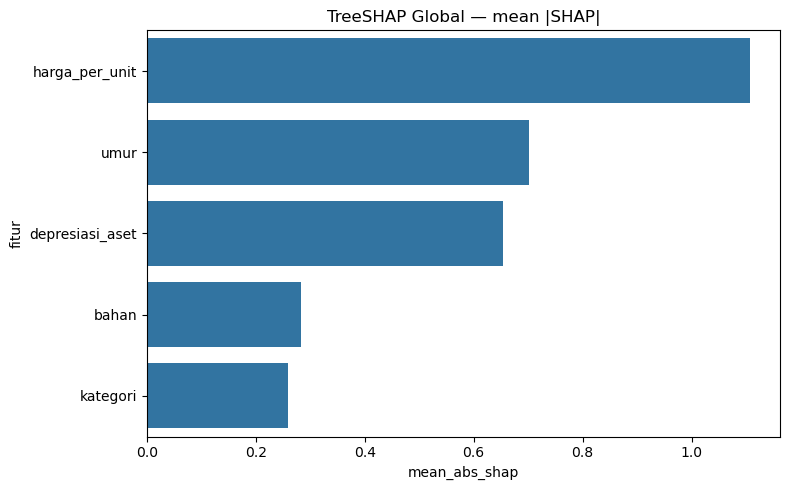

In [10]:
# --- 4. Feature importance lama (RF, skripsi) vs SHAP global baru ---
print('RF importance skripsi (notebook 05 lama):')
print('depresiasi_aset 0.2913 | umur 0.2405 | harga_per_unit 0.2219 | kategori 0.1385 | bahan 0.1077')
try:
    shap_g = pd.read_csv('../outputs/tables/shap_global.csv')
    display(shap_g)
    plt.figure(figsize=(8,5)); sns.barplot(data=shap_g, x='mean_abs_shap', y='fitur'); plt.title('TreeSHAP Global — mean |SHAP|'); plt.tight_layout(); plt.savefig('../outputs/shap/shap_global_bar.png', dpi=150); plt.show()
except FileNotFoundError:
    print('shap_global.csv belum ada — run notebook 03 dulu.')

## Kesimpulan 04

- Evaluasi dan analisis TIDAK dihapus: file asli tetap di `05_evaluation_and_analysis.ipynb`, versi revisi ini di `04_evaluation_and_analysis.ipynb`.
- Yang berubah: dari 3 kelas ke 2 kelas, dari SMOTE ke SMOTE-NC (pembanding) lalu ke scale_pos_weight (final, 2026-11-18), dari RF importance ke TreeSHAP.
- Yang tetap: classification report per kelas, confusion matrix, distribusi sebelum/sesudah balancing, dan perbandingan feature importance — itu inti Bab 4 skripsimu.
